# Detecção de fraude em transações financeiras — processo KDD

Este notebook documenta, etapa por etapa, como chegamos ao modelo usado pelo `predict.py`: o script que a aplicação
Java chama via `ProcessBuilder` para classificar uma transação como **FRAUDE** ou **APROVADO**.

Seguimos o processo **KDD** (*Knowledge Discovery in Databases*, Fayyad, Piatetsky-Shapiro e Smyth, 1996):

| Etapa | Pergunta que responde |
|---|---|
| **1. Seleção** | Quais dados e quais colunas usar? |
| **2. Pré-processamento** | Os dados têm problemas de qualidade? Precisam de limpeza? |
| **3. Transformação** | Que colunas novas, codificação e amostragem o modelo precisa? |
| **4. Mineração de dados** | Qual algoritmo funciona melhor? Por que Random Forest? |
| **5. Interpretação e avaliação** | O modelo é confiável? Onde ele erra? O resultado se sustenta? |
| **6. Modelo final** | Gerar o `models/modelo.pkl` e testar o `predict.py` como o Java fará |

**Reprodutibilidade.** O notebook importa o `train.py` e o `predict.py` e usa as mesmas funções (`preparar_features`,
`amostrar_treino`, `criar_modelo`) e a mesma semente (42). Por isso os números daqui são os mesmos do `train.py`, e a
seção 6 gera o `modelo.pkl` pelo próprio `train.py`, sem uma segunda versão do treino.

**Como rodar.** Instale `requirements-notebook.txt` no venv, baixe o dataset para `ml/data/` (ver `README.md`), abra
com `.\.venv\Scripts\python.exe -m notebook kdd_fraude.ipynb` e use *Run All*. Leva cerca de 7 minutos e
precisa de uns 6 GB de RAM livres. Use exatamente esse comando: chamar `jupyter` direto pode abrir o Jupyter de outro
Python instalado no computador, com outras versões das bibliotecas. A primeira célula confere isso.

In [1]:
import subprocess
import sys
import time

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import FuncFormatter
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
import sklearn

import predict
import train

# O modelo.pkl gerado na seção 6 precisa das mesmas versões que o predict.py usa (requirements.txt)
with open("requirements.txt") as arquivo:
    versoes_fixadas = dict(linha.strip().split("==") for linha in arquivo if "==" in linha)
versoes_instaladas = {"joblib": joblib.__version__, "numpy": np.__version__, "pandas": pd.__version__,
                      "scikit-learn": sklearn.__version__}
versoes_diferentes = {nome: (instalada, versoes_fixadas.get(nome))
                      for nome, instalada in versoes_instaladas.items() if instalada != versoes_fixadas.get(nome)}
print(f"Python {sys.version.split()[0]} | venv: {'sim' if sys.prefix != sys.base_prefix else 'NÃO'} | "
      + " | ".join(f"{nome} {versao}" for nome, versao in versoes_instaladas.items())
      + f" | matplotlib {matplotlib.__version__}")
if versoes_diferentes:
    print(f"ATENÇÃO: versões diferentes do requirements.txt (instalada, esperada): {versoes_diferentes}. "
          "Abra o notebook com .\\.venv\\Scripts\\python.exe -m notebook")

SEMENTE = train.SEMENTE
LIMIAR = predict.LIMIAR
COLUNAS = predict.COLUNAS_ENTRADA
inicio_notebook = time.time()

# Paleta validada para daltonismo: azul = transação normal, laranja = fraude; cinza = itens sem destaque
COR_NORMAL, COR_FRAUDE = "#2a78d6", "#eb6834"
CINZA_CLARO, CINZA_ESCURO = "#c3c2b7", "#898781"
SUPERFICIE, TINTA, TINTA_2, GRADE = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9"
AZUL_SEQUENCIAL = LinearSegmentedColormap.from_list(
    "azul", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "figure.dpi": 110, "font.size": 10, "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "text.color": TINTA, "axes.titlecolor": TINTA, "axes.labelcolor": TINTA_2,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.edgecolor": CINZA_CLARO, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRADE, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "xtick.color": CINZA_ESCURO, "ytick.color": CINZA_ESCURO, "xtick.labelcolor": TINTA_2,
    "ytick.labelcolor": TINTA_2, "legend.frameon": False, "lines.linewidth": 2,
})


def milhar(n):
    return f"{n:,.0f}".replace(",", ".")


def pct(x, casas=2):
    return f"{x * 100:.{casas}f}%".replace(".", ",")


def metricas(nome, y_real, probabilidade, tempo=None):
    previsto = (np.asarray(probabilidade) >= LIMIAR).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_real, previsto, labels=[0, 1]).ravel()
    return {
        "modelo": nome,
        "acurácia": accuracy_score(y_real, previsto),
        "precisão": precision_score(y_real, previsto, zero_division=0),
        "recall": recall_score(y_real, previsto),
        "F1": f1_score(y_real, previsto),
        "AP": average_precision_score(y_real, probabilidade),
        "fraudes detectadas": vp, "fraudes que passaram": fn, "normais bloqueadas": fp,
        "treino (s)": tempo,
    }


def tabela_metricas(linhas):
    tabela = pd.DataFrame(linhas).set_index("modelo")
    if tabela["treino (s)"].isna().all():
        tabela = tabela.drop(columns="treino (s)")
    return tabela.style.format({
        "acurácia": "{:.4%}", "precisão": "{:.2%}", "recall": "{:.2%}", "F1": "{:.2%}", "AP": "{:.4f}",
        "treino (s)": "{:.0f}", "fraudes detectadas": "{:,}", "fraudes que passaram": "{:,}",
        "normais bloqueadas": "{:,}"}, na_rep="—", decimal=",", thousands=".")


def plotar_matriz(ax, y_real, probabilidade, titulo):
    cm = confusion_matrix(y_real, (np.asarray(probabilidade) >= LIMIAR).astype(int), labels=[0, 1])
    por_linha = cm / cm.sum(axis=1, keepdims=True)
    norma = LogNorm(vmin=1, vmax=cm.max())
    ax.imshow(np.maximum(cm, 1), cmap=AZUL_SEQUENCIAL, norm=norma)
    nomes = [["normais aprovadas", "normais bloqueadas\n(falso alarme)"],
             ["fraudes que passaram", "fraudes detectadas"]]
    for i in range(2):
        for j in range(2):
            cor = "#ffffff" if norma(max(cm[i, j], 1)) > 0.55 else TINTA
            ax.text(j, i, f"{milhar(cm[i, j])}\n{pct(por_linha[i, j])} da linha\n{nomes[i][j]}",
                    ha="center", va="center", color=cor, fontsize=9.5, linespacing=1.4)
    ax.set_xticks([0, 1], ["APROVADO", "FRAUDE"])
    ax.set_yticks([0, 1], ["normal", "fraude"])
    ax.set_xlabel("previsto pelo modelo")
    ax.set_ylabel("real")
    ax.set_title(titulo)
    ax.grid(False)
    for lado in ax.spines.values():
        lado.set_visible(False)

Python 3.12.5 | venv: sim | joblib 1.6.0 | numpy 2.5.4 | pandas 3.1.1 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 1. Seleção

O dataset é o **PaySim** (Lopez-Rojas, Elmir e Axelsson, 2016), disponível no
[Kaggle](https://www.kaggle.com/datasets/ealaxi/paysim1). Ele simula 30 dias (743 horas) de transações de dinheiro
por celular, calibradas com dados reais de um serviço de *mobile money* de um país africano, e marca quais são fraude.

Usamos um dataset sintético porque dados reais de fraude bancária não são públicos. E, diferente de outros datasets
públicos (como o *Credit Card Fraud*, com colunas anonimizadas `V1`…`V28`), as colunas do PaySim têm significado: são
dados que a aplicação Java consegue de fato enviar.

| Coluna | Significado |
|---|---|
| `step` | hora da simulação (1 a 743) |
| `type` | `CASH_IN` (depósito), `CASH_OUT` (saque), `DEBIT` (débito), `PAYMENT` (pagamento a comerciante), `TRANSFER` (transferência) |
| `amount` | valor da transação |
| `nameOrig` | conta de quem envia |
| `oldbalanceOrg` / `newbalanceOrig` | saldo de quem envia, antes e depois |
| `nameDest` | conta de quem recebe (`C` = cliente, `M` = comerciante) |
| `oldbalanceDest` / `newbalanceDest` | saldo de quem recebe, antes e depois |
| `isFraud` | **1 = fraude** — é o que o modelo aprende a prever |
| `isFlaggedFraud` | 1 = marcada pela regra antiga do sistema (transferências acima de 200 mil) |

In [2]:
inicio = time.time()
df = pd.read_csv(train.CAMINHO_DATASET)
print(f"{milhar(len(df))} transações × {df.shape[1]} colunas | "
      f"{df.memory_usage(deep=True).sum() / 1e9:.1f} GB em memória | lido em {time.time() - inicio:.0f}s")
df.head()

6.362.620 transações × 11 colunas | 1.5 GB em memória | lido em 8s


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


### 1.1 Quantas fraudes existem

In [3]:
fraude = df["isFraud"] == 1
print(f"Fraudes: {milhar(fraude.sum())} de {milhar(len(df))} transações ({pct(fraude.mean())})")
print(f"Um 'modelo' que sempre responde APROVADO acertaria {pct(1 - fraude.mean())} das vezes "
      "e não detectaria nenhuma fraude.")

Fraudes: 8.213 de 6.362.620 transações (0,13%)
Um 'modelo' que sempre responde APROVADO acertaria 99,87% das vezes e não detectaria nenhuma fraude.


As classes são **muito desbalanceadas**: só 0,13% das transações são fraude. Isso define duas decisões das próximas
etapas: a **acurácia não serve como métrica** (ela fica alta mesmo sem detectar nada) e o treino precisa de uma
estratégia para o desbalanceamento (seção 3.5).

### 1.2 Fraude por tipo de transação

isFraud,normais,fraudes,total,% de fraude
type,,,,
CASH_OUT,2.233.384,4.116,2.237.500,"0,184"
PAYMENT,2.151.495,0,2.151.495,"0,000"
CASH_IN,1.399.284,0,1.399.284,"0,000"
TRANSFER,528.812,4.097,532.909,"0,769"
DEBIT,41.432,0,41.432,"0,000"


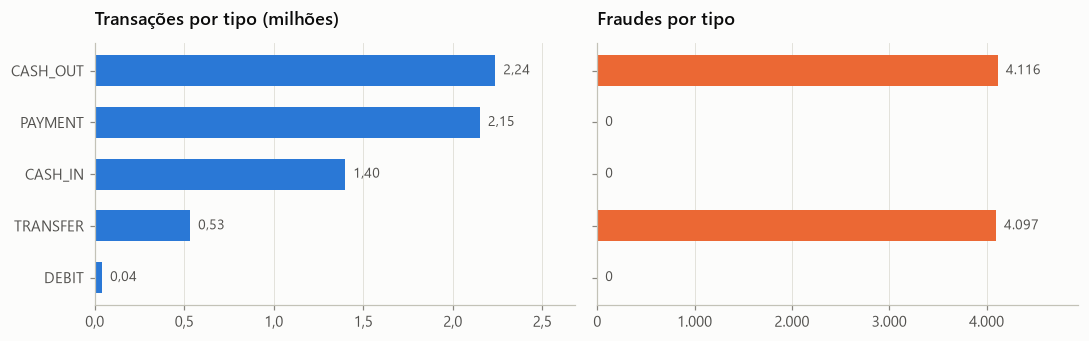

In [4]:
por_tipo = pd.crosstab(df["type"], df["isFraud"]).rename(columns={0: "normais", 1: "fraudes"})
por_tipo["total"] = por_tipo.sum(axis=1)
por_tipo["% de fraude"] = (por_tipo["fraudes"] / por_tipo["total"] * 100).round(3)
por_tipo = por_tipo.sort_values("total", ascending=False)
display(por_tipo.style.format(precision=3, thousands=".", decimal=","))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
ax1.barh(por_tipo.index, por_tipo["total"] / 1e6, color=COR_NORMAL, height=0.6)
ax2.barh(por_tipo.index, por_tipo["fraudes"], color=COR_FRAUDE, height=0.6)
ax1.set_title("Transações por tipo (milhões)")
ax2.set_title("Fraudes por tipo")
for ax, valores, formato in ((ax1, por_tipo["total"] / 1e6, lambda v: f"{v:.2f}".replace(".", ",")),
                             (ax2, por_tipo["fraudes"], milhar)):
    for posicao, valor in enumerate(valores):
        ax.text(valor, posicao, "  " + formato(valor), va="center", color=TINTA_2, fontsize=9)
    ax.set_xlim(0, valores.max() * 1.2)
    ax.grid(axis="y", visible=False)
ax1.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
ax2.xaxis.set_major_formatter(FuncFormatter(lambda v, _: milhar(v)))
ax1.invert_yaxis()
plt.tight_layout()
plt.show()

**Fraude só acontece em `TRANSFER` e `CASH_OUT`**, praticamente meio a meio. Isso bate com o golpe que o simulador
reproduz: o fraudador toma a conta da vítima, **transfere** o dinheiro para uma conta dele e depois **saca**. Os outros
três tipos nunca são fraude. Mantemos todos os tipos no modelo (codificados na seção 3.2): assim ele também aprende que
`PAYMENT`, `CASH_IN` e `DEBIT` são seguros, e o `predict.py` aceita qualquer tipo.

### 1.3 Identificadores das contas (`nameOrig`, `nameDest`)

In [5]:
contas = pd.DataFrame({
    "contas diferentes": [df["nameOrig"].nunique(), df["nameDest"].nunique()],
    "transações": [len(df), len(df)],
}, index=["nameOrig (quem envia)", "nameDest (quem recebe)"])
contas["transações por conta"] = (contas["transações"] / contas["contas diferentes"]).round(2)
display(contas.style.format(precision=2, thousands=".", decimal=","))
pd.crosstab(df["type"], df["nameDest"].str[0].rename("prefixo de nameDest")).style.format(thousands=".")

,contas diferentes,transações,transações por conta
nameOrig (quem envia),6.353.307,6.362.620,"1,00"
nameDest (quem recebe),2.722.362,6.362.620,"2,34"


prefixo de nameDest,C,M
type,,
CASH_IN,1.399.284,0
CASH_OUT,2.237.500,0
DEBIT,41.432,0
PAYMENT,0,2.151.495
TRANSFER,532.909,0


**Descartamos os identificadores.** Quase toda conta de origem aparece uma única vez (1,00 transação por conta), então
não existe histórico por cliente para aproveitar. Usar o código da conta como coluna faria o modelo decorar códigos
arbitrários, que não se repetem em transações novas. O prefixo `M` (comerciante) aparece só em `PAYMENT`, informação que
a coluna `type` já carrega.

### 1.4 A regra antiga (`isFlaggedFraud`)

In [6]:
display(pd.crosstab(df["isFlaggedFraud"], df["isFraud"]).style.format(thousands="."))
print(f"A regra marcou {milhar(df['isFlaggedFraud'].sum())} transações: "
      f"precisão {pct(precision_score(df['isFraud'], df['isFlaggedFraud']))}, "
      f"recall {pct(recall_score(df['isFraud'], df['isFlaggedFraud']))}")

isFraud,0,1
isFlaggedFraud,,
0,6.354.407,8.197
1,0,16


A regra marcou 16 transações: precisão 100,00%, recall 0,19%


A regra antiga do sistema acertou todas as vezes em que disparou, mas **só disparou 16 vezes**: deixou passar 99,8% das
fraudes. Ela mostra por que um modelo de aprendizado é necessário. **Não a usamos como coluna** porque ela é a saída de
outro sistema, não uma característica da transação: o Java não teria essa informação. Ela volta na etapa 4 só como
comparação.

### 1.5 Hora do dia (`step`)

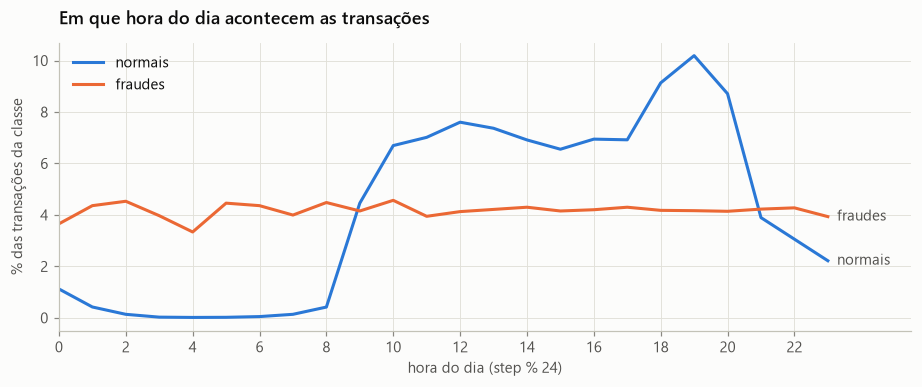

Taxa de fraude por hora: de 0,053% (hora 19) a 22,30% (hora 5)


In [7]:
hora = df["step"] % 24
distribuicao = pd.crosstab(hora, df["isFraud"], normalize="columns") * 100
taxa_por_hora = df.groupby(hora)["isFraud"].mean()

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(distribuicao.index, distribuicao[0], color=COR_NORMAL, label="normais")
ax.plot(distribuicao.index, distribuicao[1], color=COR_FRAUDE, label="fraudes")
for coluna, cor, nome in ((0, COR_NORMAL, "normais"), (1, COR_FRAUDE, "fraudes")):
    ax.annotate(nome, (23, distribuicao[coluna].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=TINTA_2)
ax.set(title="Em que hora do dia acontecem as transações", xlabel="hora do dia (step % 24)",
       ylabel="% das transações da classe", xticks=range(0, 24, 2), xlim=(0, 25.5))
ax.legend(loc="upper left")
plt.show()
print(f"Taxa de fraude por hora: de {pct(taxa_por_hora.min(), 3)} (hora {taxa_por_hora.idxmin()}) "
      f"a {pct(taxa_por_hora.max())} (hora {taxa_por_hora.idxmax()})")

As transações normais se concentram no horário comercial, enquanto as fraudes se espalham de forma quase uniforme pelas
24 horas. Por isso, de madrugada a taxa de fraude chega a 22%. A hora carrega informação, mas **não entra no modelo
agora**: ela obrigaria o Java a enviar mais um campo e, como mostra a seção 5.6, não melhora o resultado.

### 1.6 Resultado da seleção

| Decisão | Colunas |
|---|---|
| **Usadas** | `type`, `amount`, `oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest`, `newbalanceDest` |
| **Alvo** | `isFraud` |
| **Descartadas** | `nameOrig`, `nameDest` (identificadores), `isFlaggedFraud` (saída de outro sistema), `step` (testada na seção 5.6) |

## 2. Pré-processamento

### 2.1 Qualidade dos dados

In [8]:
numericas = df.select_dtypes("number")
qualidade = pd.DataFrame({
    "valores faltando": df.isna().sum(),
    "valores negativos": (numericas < 0).sum().reindex(df.columns),
}).fillna(0).astype(int)
display(qualidade.T)
print(f"Linhas duplicadas: {df.duplicated().sum()}")

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
valores faltando,0,0,0,0,0,0,0,0,0,0,0
valores negativos,0,0,0,0,0,0,0,0,0,0,0


Linhas duplicadas: 0


O dataset não tem valores faltando, negativos nem linhas duplicadas: **não há o que imputar ou remover**.

### 2.2 Valor das transações

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
normal,"6.354.407,00","178.197,04","596.236,98","0,01","13.368,40","74.684,72","208.364,76","92.445.516,64"
fraude,"8.213,00","1.467.967,30","2.404.252,95","0,00","127.091,33","441.423,44","1.517.771,48","10.000.000,00"


Maior fraude: 10.000.000 | fraudes de exatamente 10 milhões: 287 | fraudes com valor 0: 16


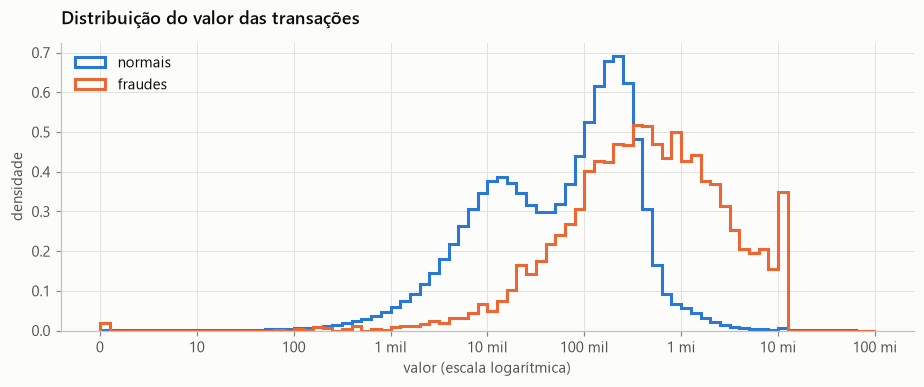

In [9]:
display(df.groupby("isFraud")["amount"].describe().rename(index={0: "normal", 1: "fraude"})
        .style.format(precision=2, thousands=".", decimal=","))
valor_fraude = df.loc[fraude, "amount"]
print(f"Maior fraude: {milhar(valor_fraude.max())} | fraudes de exatamente 10 milhões: "
      f"{milhar((valor_fraude == 10_000_000).sum())} | fraudes com valor 0: {milhar((valor_fraude == 0).sum())}")

faixas = np.linspace(0, 8, 81)
fig, ax = plt.subplots(figsize=(10, 3.4))
for classe, cor, nome in ((0, COR_NORMAL, "normais"), (1, COR_FRAUDE, "fraudes")):
    ax.hist(np.log10(df.loc[df["isFraud"] == classe, "amount"] + 1), bins=faixas, density=True,
            histtype="step", linewidth=2, color=cor, label=nome)
ax.set_xticks(range(9), ["0", "10", "100", "1 mil", "10 mil", "100 mil", "1 mi", "10 mi", "100 mi"])
ax.set(title="Distribuição do valor das transações", xlabel="valor (escala logarítmica)",
       ylabel="densidade")
ax.legend(loc="upper left")
plt.show()

Fraudes envolvem valores bem maiores: a mediana da fraude é **441 mil**, contra **75 mil** das transações normais.
Nenhuma fraude passa de **10 milhões** (287 têm exatamente esse valor, um teto do simulador), enquanto transações normais
chegam a 92 milhões. Há também 16 fraudes de valor 0.

**Decisão: não removemos *outliers*.** Valores extremos fazem parte do sinal de fraude, e o modelo precisa ver os dados
do jeito que eles vão chegar do Java.

### 2.3 Consistência dos saldos

Olhamos só `TRANSFER` e `CASH_OUT`, os dois tipos em que existe fraude, para comparar normais e fraudes nas mesmas
condições. Um saldo "fecha" quando *saldo antes − valor = saldo depois* (origem) ou *saldo antes + valor = saldo depois*
(destino).

,normais,fraudes
valor = saldo inteiro da origem,"0,0%","97,8%"
origem termina com saldo 0,"90,1%","98,1%"
origem já começa com saldo 0,"47,4%","0,5%"
saldo da origem não fecha,"90,6%","0,5%"
destino fica 0 → 0,"0,1%","49,6%"
saldo do destino não fecha,"22,6%","56,5%"


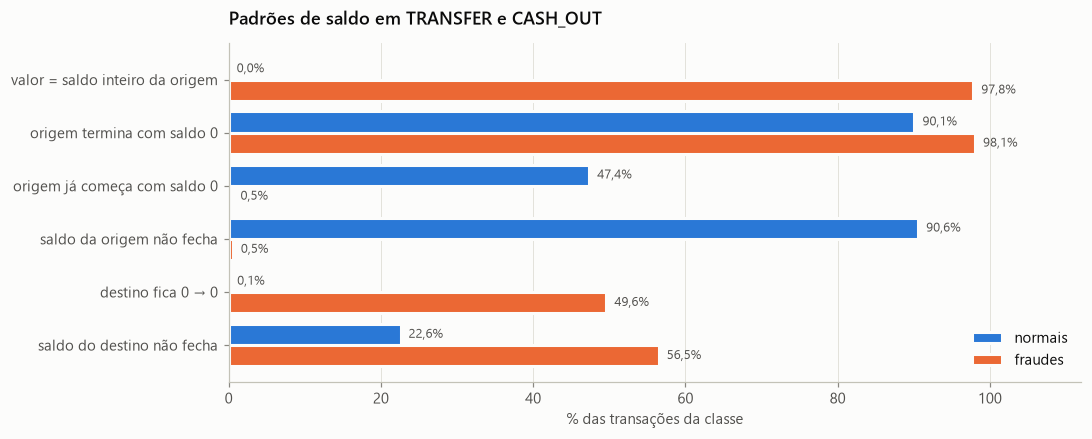

In [10]:
transf_saque = df[df["type"].isin(["TRANSFER", "CASH_OUT"])]
padroes = pd.DataFrame({
    "valor = saldo inteiro da origem": (transf_saque["amount"] - transf_saque["oldbalanceOrg"]).abs() < 0.01,
    "origem termina com saldo 0": transf_saque["newbalanceOrig"] == 0,
    "origem já começa com saldo 0": transf_saque["oldbalanceOrg"] == 0,
    "saldo da origem não fecha": (transf_saque["newbalanceOrig"] + transf_saque["amount"]
                                  - transf_saque["oldbalanceOrg"]).abs() > 0.01,
    "destino fica 0 → 0": (transf_saque["oldbalanceDest"] == 0) & (transf_saque["newbalanceDest"] == 0),
    "saldo do destino não fecha": (transf_saque["oldbalanceDest"] + transf_saque["amount"]
                                   - transf_saque["newbalanceDest"]).abs() > 0.01,
}).groupby(transf_saque["isFraud"]).mean().T
padroes.columns = ["normais", "fraudes"]
display(padroes.style.format("{:.1%}", decimal=","))

posicoes = np.arange(len(padroes))
fig, ax = plt.subplots(figsize=(10, 4))
for deslocamento, coluna, cor in ((-0.2, "normais", COR_NORMAL), (0.2, "fraudes", COR_FRAUDE)):
    ax.barh(posicoes + deslocamento, padroes[coluna] * 100, height=0.4, color=cor, label=coluna,
            edgecolor=SUPERFICIE, linewidth=2)
    for y, valor in zip(posicoes + deslocamento, padroes[coluna]):
        ax.text(valor * 100, y, "  " + pct(valor, 1), va="center", color=TINTA_2, fontsize=8.5)
ax.set_yticks(posicoes, padroes.index)
ax.invert_yaxis()
ax.set_xlim(0, 112)
ax.set(title="Padrões de saldo em TRANSFER e CASH_OUT", xlabel="% das transações da classe")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.show()

Aqui aparece o comportamento que separa fraude de transação normal:

- **O fraudador esvazia a conta da vítima.** Em 97,8% das fraudes o valor é exatamente o saldo inteiro da origem;
  nas normais, isso quase nunca acontece (0,0%). Por consequência, o saldo da origem *fecha* na fraude e quase nunca
  fecha nas normais (90,6% não fecham).
- **Metade das fraudes não mexe no saldo do destino** (0 → 0 em 49,6%, contra 0,1% das normais).
- **Muitas transações normais têm saldos incoerentes**, como contas que começam com saldo 0 (47,4%). É uma
  característica do simulador, não um erro a corrigir.

**Decisão: não corrigimos nem removemos esses saldos.** A incoerência é justamente o sinal de fraude; "consertá-la"
apagaria o padrão. E o modelo precisa ver os dados do jeito que vão chegar do Java.

## 3. Transformação

### 3.1 Novas colunas: erro de saldo

A seção 2.3 mostrou que o sinal está em **o saldo fechar ou não** com o valor. Uma árvore de decisão compara uma coluna
por vez com um limite, então essa conta (que envolve três colunas) é difícil de ela aprender sozinha. Por isso criamos
duas colunas com a diferença pronta:

- `erroSaldoOrigem = newbalanceOrig + amount − oldbalanceOrg` → **0 quando o saldo de quem envia fecha**
- `erroSaldoDestino = oldbalanceDest + amount − newbalanceDest` → **0 quando o saldo de quem recebe fecha**

Elas são calculadas pela função `preparar_features` do `predict.py`, a mesma que o `train.py` usa. Treino e predição
fazem exatamente a mesma conta, o que evita o erro clássico de o modelo receber em produção dados calculados de um
jeito diferente do treino.

In [11]:
X = predict.preparar_features(df[COLUNAS])
y = df["isFraud"]
regra_antiga = df["isFlaggedFraud"]  # só para comparação na etapa 4
passo = df["step"]                   # só para os testes da seção 5.6
del df, transf_saque, numericas
X.head()

,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,erroSaldoOrigem,erroSaldoDestino
0,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0,0.0,9839.64
1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0,0.0,1864.28
2,TRANSFER,181.00,181.0,0.00,0.0,0.0,0.0,181.00
3,CASH_OUT,181.00,181.0,0.00,21182.0,0.0,0.0,21363.00
4,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0,0.0,11668.14


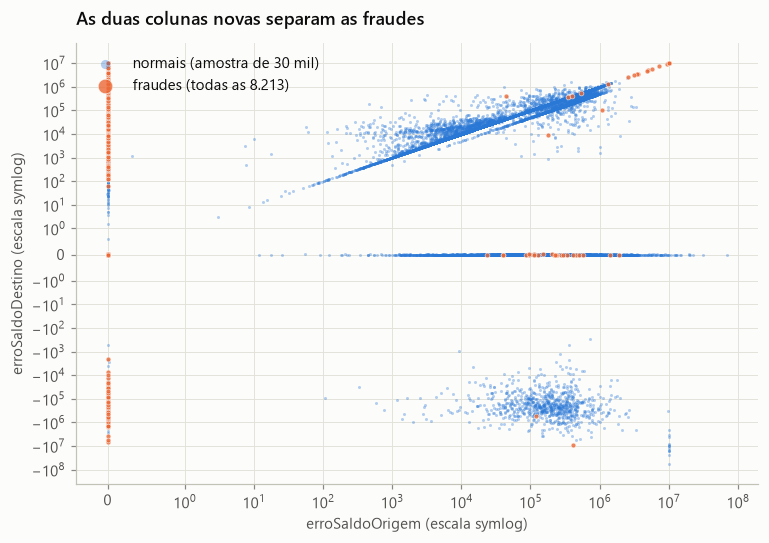

,erroSaldoOrigem,erroSaldoDestino
normais,"20,0%","34,2%"
fraudes,"99,5%","43,5%"


In [12]:
normais = X[y == 0].sample(30_000, random_state=SEMENTE)
fraudes = X[y == 1]
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.scatter(normais["erroSaldoOrigem"], normais["erroSaldoDestino"], s=4, color=COR_NORMAL, alpha=0.35,
           linewidths=0, label="normais (amostra de 30 mil)")
ax.scatter(fraudes["erroSaldoOrigem"], fraudes["erroSaldoDestino"], s=10, color=COR_FRAUDE, alpha=0.8,
           edgecolors=SUPERFICIE, linewidths=0.4, label=f"fraudes (todas as {milhar(len(fraudes))})")
ax.set_xscale("symlog", linthresh=1)
ax.set_yscale("symlog", linthresh=1)
ax.set(title="As duas colunas novas separam as fraudes", xlabel="erroSaldoOrigem (escala symlog)",
       ylabel="erroSaldoDestino (escala symlog)")
ax.legend(loc="upper left", markerscale=3)
plt.show()

erro_zero = pd.DataFrame({coluna: (X[coluna].abs() < 0.01).groupby(y).mean()
                          for coluna in ["erroSaldoOrigem", "erroSaldoDestino"]})
erro_zero.index = ["normais", "fraudes"]
display(erro_zero.style.format("{:.1%}", decimal=",").set_caption("% das transações em que o saldo fecha (erro = 0)"))

Em **99,5% das fraudes o saldo da origem fecha** (`erroSaldoOrigem` = 0, a coluna vertical à esquerda do gráfico),
contra só 20% das transações normais, que se espalham pela diagonal e pelas faixas horizontais. É essa separação que o
modelo vai explorar. O erro de saldo do destino separa menos sozinho (43,5% contra 34,2%), mas ajuda a desempatar os
casos em que a origem não basta.

### 3.2 Codificação do tipo

`type` é texto. Dentro do modelo ele vira cinco colunas 0/1 (*one-hot*), uma por tipo, com a lista de tipos fixa em
`predict.TIPOS`. A codificação faz parte do *pipeline* salvo no `.pkl`, então o `predict.py` passa o texto direto.

### 3.3 Escala

O Random Forest decide comparando cada coluna com limites ("valor > 200 mil?"), então **não precisa normalizar** as
colunas: multiplicar uma coluna por 1.000 não muda as divisões das árvores. Só a regressão logística da etapa 4, que é
sensível à escala, recebe uma padronização (`StandardScaler`).

### 3.4 Divisão treino/teste e desbalanceamento

In [13]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMENTE)
X_amostra, y_amostra = train.amostrar_treino(X_treino, y_treino)

divisao = pd.DataFrame({
    "transações": [len(y), len(y_treino), len(y_amostra), len(y_teste)],
    "fraudes": [y.sum(), y_treino.sum(), y_amostra.sum(), y_teste.sum()],
}, index=["dataset completo", "treino (80%)", "amostra usada no treino", "teste (20%)"])
divisao["% de fraude"] = divisao["fraudes"] / divisao["transações"]
divisao.style.format({"transações": "{:,}", "fraudes": "{:,}", "% de fraude": "{:.2%}"}, decimal=",", thousands=".")

,transações,fraudes,% de fraude
dataset completo,6.362.620,8.213,"0,13%"
treino (80%),5.090.096,6.570,"0,13%"
amostra usada no treino,1.006.570,6.570,"0,65%"
teste (20%),1.272.524,1.643,"0,13%"


- **Divisão 80/20 estratificada** (mesma semente do `train.py`): o teste tem 1,27 milhão de transações que o modelo nunca
  vê no treino, **com a proporção real de 0,13% de fraude**. Avaliar com a proporção real é o que torna as métricas
  honestas.
- **Amostragem no treino:** usamos todas as fraudes do treino e 1 milhão de transações normais sorteadas. A fraude passa
  de 0,13% para 0,65%, o modelo vê mais exemplos do que importa e o treino fica 5 vezes mais rápido (cerca de 25 s).
  A seção 5.6 mostra que o resultado se mantém com outras amostras.
- Alternativas como SMOTE (gerar fraudes sintéticas) não foram necessárias e poderiam distorcer justamente os padrões
  de saldo da seção 2.3.

## 4. Mineração de dados

Comparamos seis abordagens, **todas nas mesmas condições**: mesma amostra de treino, mesmo teste e mesmo limiar (0,5).

| Abordagem | Por que está na comparação |
|---|---|
| Sempre APROVADO | referência ingênua: mostra o que a acurácia esconde |
| Regra antiga (`isFlaggedFraud`) | o que o sistema fazia antes |
| Regressão logística | modelo linear simples e interpretável |
| Árvore de decisão | uma única árvore, para medir o ganho de usar uma floresta |
| Random Forest **sem** as colunas de erro de saldo | mede o ganho das colunas criadas na seção 3.1 |
| **Random Forest (escolhido)** | 100 árvores, profundidade máxima 15, com as colunas de erro de saldo |

**Métricas** (a classe positiva é a fraude):

- **Precisão:** dos alertas de fraude, quantos eram mesmo fraude. Alta = poucos clientes bloqueados por engano.
- **Recall:** das fraudes que existiam, quantas o modelo pegou. Alto = pouco prejuízo.
- **F1:** equilíbrio entre precisão e recall (média harmônica).
- **AP** (*average precision*): resume a curva precisão × recall da seção 5.2; não depende do limiar.
- **Acurácia:** aparece só para mostrar que, com 0,13% de fraude, ela engana.

In [14]:
def preprocessamento(padronizar):
    return ColumnTransformer(
        [("tipo", OneHotEncoder(categories=[predict.TIPOS], handle_unknown="ignore"), ["type"])],
        remainder=StandardScaler() if padronizar else "passthrough")


todas = list(X.columns)
modelos = {
    "Sempre APROVADO": (DummyClassifier(strategy="most_frequent"), todas),
    "Regressão logística": (Pipeline([("preprocessamento", preprocessamento(True)),
                                      ("logistica", LogisticRegression(max_iter=2000))]), todas),
    "Árvore de decisão": (Pipeline([("preprocessamento", preprocessamento(False)),
                                    ("arvore", DecisionTreeClassifier(max_depth=15, min_samples_leaf=2,
                                                                      random_state=SEMENTE))]), todas),
    "Random Forest sem erro de saldo": (train.criar_modelo(), COLUNAS),
    "Random Forest (escolhido)": (train.criar_modelo(), todas),
}

resultados, probabilidades = [], {}
for nome, (modelo, colunas) in modelos.items():
    inicio = time.time()
    modelo.fit(X_amostra[colunas], y_amostra)
    tempo = time.time() - inicio
    probabilidades[nome] = modelo.predict_proba(X_teste[colunas])[:, 1]
    resultados.append(metricas(nome, y_teste, probabilidades[nome], tempo))
    print(f"{nome}: treinado em {tempo:.0f}s")

probabilidades["Regra antiga (isFlaggedFraud)"] = regra_antiga.loc[X_teste.index].to_numpy()
resultados.insert(1, metricas("Regra antiga (isFlaggedFraud)", y_teste,
                              probabilidades["Regra antiga (isFlaggedFraud)"]))
comparacao = pd.DataFrame(resultados).set_index("modelo")
tabela_metricas(resultados)

Sempre APROVADO: treinado em 0s


Regressão logística: treinado em 2s


Árvore de decisão: treinado em 11s


Random Forest sem erro de saldo: treinado em 21s


Random Forest (escolhido): treinado em 22s


,acurácia,precisão,recall,F1,AP,fraudes detectadas,fraudes que passaram,normais bloqueadas,treino (s)
modelo,,,,,,,,,
Sempre APROVADO,"99,8709%","0,00%","0,00%","0,00%","0,0013",0,1.643,0,0
Regra antiga (isFlaggedFraud),"99,8709%","0,00%","0,00%","0,00%","0,0013",0,1.643,0,—
Regressão logística,"99,9039%","65,28%","54,60%","59,46%","0,6152",897,746,477,2
Árvore de decisão,"99,9951%","96,58%","99,76%","98,14%","0,9981",1.639,4,58,11
Random Forest sem erro de saldo,"99,9635%","92,44%","78,15%","84,70%","0,9075",1.284,359,105,21
Random Forest (escolhido),"99,9997%","100,00%","99,76%","99,88%","0,9983",1.639,4,0,22


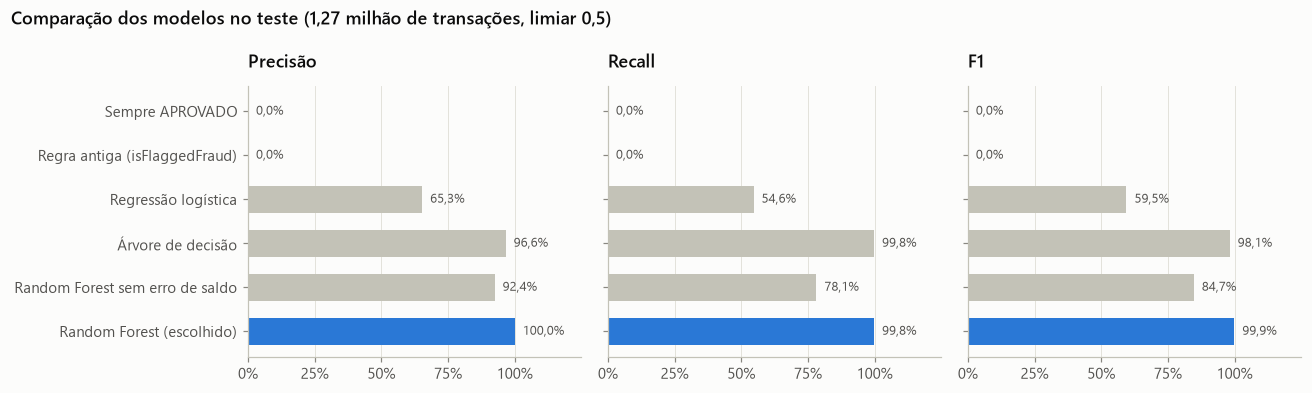

In [15]:
escolhido = "Random Forest (escolhido)"
fig, eixos = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, metrica in zip(eixos, ["precisão", "recall", "F1"]):
    valores = comparacao[metrica]
    cores = [COR_NORMAL if nome == escolhido else CINZA_CLARO for nome in valores.index]
    ax.barh(valores.index, valores * 100, color=cores, height=0.6)
    for posicao, valor in enumerate(valores):
        ax.text(valor * 100, posicao, "  " + pct(valor, 1), va="center", color=TINTA_2, fontsize=8.5)
    ax.set_title(metrica.capitalize())
    ax.set_xlim(0, 125)
    ax.set_xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
    ax.grid(axis="y", visible=False)
eixos[0].invert_yaxis()
fig.suptitle("Comparação dos modelos no teste (1,27 milhão de transações, limiar 0,5)", x=0.01, ha="left",
             fontsize=12, fontweight="semibold")
plt.tight_layout()
plt.show()

O que a comparação mostra:

- **A acurácia engana.** "Sempre APROVADO" tem 99,87% de acurácia e não pega nenhuma fraude. Por isso as decisões usam
  precisão, recall e F1.
- **A regra antiga não aparece no teste.** Por acaso, nenhum dos 16 alertas dela caiu nos 20% de teste. No dataset
  inteiro, ela pega só 0,19% das fraudes (seção 1.4).
- **Um modelo linear não basta.** A regressão logística pega só 54,6% das fraudes, e 1 em cada 3 alertas dela é falso.
  O padrão de fraude ("o valor é igual ao saldo **e** a conta fica zerada") é uma combinação de condições, e não uma
  soma ponderada das colunas, que é o que um modelo linear consegue representar.
- **As colunas de erro de saldo são o maior ganho.** O mesmo Random Forest sem elas detecta 78,1% das fraudes e bloqueia
  105 transações normais; com elas, 99,8% e nenhuma. Isso confirma a decisão da seção 3.1.
- **A floresta elimina os falsos alarmes da árvore.** Uma única árvore já detecta as mesmas 1.639 fraudes, mas bloqueia
  58 clientes normais por engano. As 100 árvores do Random Forest votam juntas e zeram esses falsos alarmes, ao custo de
  uns 13 segundos a mais de treino.

**Por isso o escolhido foi o Random Forest com as colunas de erro de saldo:** é o único que chega ao recall máximo sem
nenhum falso alarme.

## 5. Interpretação e avaliação

A partir daqui avaliamos em detalhe o modelo escolhido.

### 5.1 Matriz de confusão

              precision    recall  f1-score   support

    APROVADO     1.0000    1.0000    1.0000   1270881
      FRAUDE     1.0000    0.9976    0.9988      1643

    accuracy                         1.0000   1272524
   macro avg     1.0000    0.9988    0.9994   1272524
weighted avg     1.0000    1.0000    1.0000   1272524



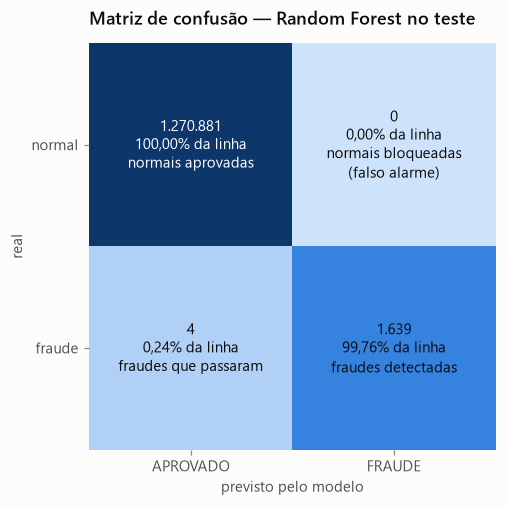

In [16]:
modelo_final = modelos[escolhido][0]
probabilidade_final = probabilidades[escolhido]
print(classification_report(y_teste, (probabilidade_final >= LIMIAR).astype(int),
                            target_names=["APROVADO", "FRAUDE"], digits=4))

fig, ax = plt.subplots(figsize=(6.4, 4.8))
plotar_matriz(ax, y_teste, probabilidade_final, "Matriz de confusão — Random Forest no teste")
plt.show()

No teste, com 1.272.524 transações que o modelo nunca viu:

- **1.639 de 1.643 fraudes detectadas** (recall de 99,76%). Só 4 passaram; elas são analisadas na seção 5.5.
- **Nenhuma transação normal bloqueada** (precisão de 100%): nenhum cliente teria a transação recusada por engano.

As cores da matriz estão em escala logarítmica: sem isso, a célula de 1,27 milhão apagaria todas as outras.

### 5.2 Curva precisão × recall

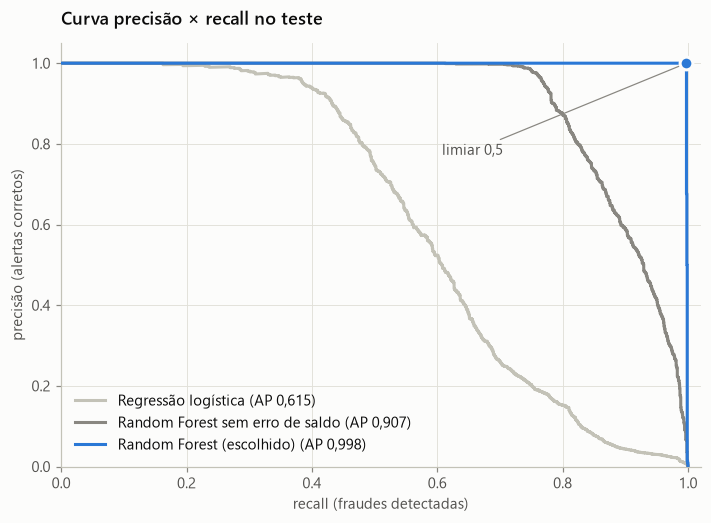

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for nome, cor, camada in (("Regressão logística", CINZA_CLARO, 1),
                          ("Random Forest sem erro de saldo", CINZA_ESCURO, 2),
                          (escolhido, COR_NORMAL, 3)):
    precisao, recall, _ = precision_recall_curve(y_teste, probabilidades[nome])
    ax.plot(recall, precisao, color=cor, zorder=camada,
            label=f"{nome} (AP {average_precision_score(y_teste, probabilidades[nome]):.3f})".replace(".", ","))
ponto = (recall_score(y_teste, probabilidade_final >= LIMIAR), precision_score(y_teste, probabilidade_final >= LIMIAR))
ax.scatter(*ponto, s=70, color=COR_NORMAL, edgecolors=SUPERFICIE, linewidths=2, zorder=4)
ax.annotate("limiar 0,5", ponto, xytext=(-160, -60), textcoords="offset points", color=TINTA_2,
            arrowprops={"arrowstyle": "-", "color": CINZA_ESCURO, "linewidth": 0.8})
ax.set(xlim=(0, 1.02), ylim=(0, 1.05), xlabel="recall (fraudes detectadas)",
       ylabel="precisão (alertas corretos)", title="Curva precisão × recall no teste")
ax.legend(loc="lower left")
plt.show()

A curva mostra todos os equilíbrios possíveis entre precisão e recall conforme o limiar muda; quanto mais ela encosta no
canto superior direito, melhor. A curva do Random Forest escolhido fica colada no canto (AP próximo de 1), bem acima do
mesmo algoritmo sem as colunas de erro de saldo e da regressão logística.

### 5.3 Escolha do limiar

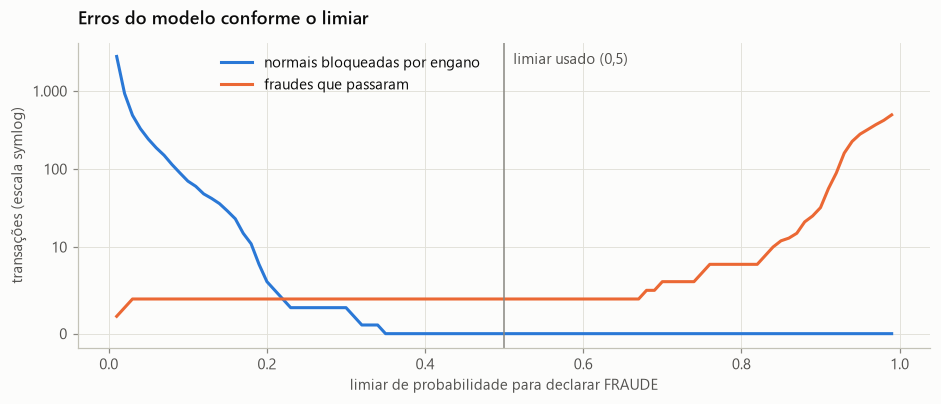

limiar,0.05,0.10,0.20,0.30,0.40,0.50,0.60,0.70,0.80,0.90
normais bloqueadas,242,70,6,3,0,0,0,0,0,0
fraudes que passaram,4,4,4,4,4,4,4,6,8,32


In [18]:
limiares = np.round(np.arange(0.01, 1.0, 0.01), 2)
real = y_teste.to_numpy()
falsos_alarmes = np.array([((probabilidade_final >= t) & (real == 0)).sum() for t in limiares])
fraudes_perdidas = np.array([((probabilidade_final < t) & (real == 1)).sum() for t in limiares])

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(limiares, falsos_alarmes, color=COR_NORMAL, label="normais bloqueadas por engano")
ax.plot(limiares, fraudes_perdidas, color=COR_FRAUDE, label="fraudes que passaram")
ax.set_yscale("symlog", linthresh=10)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: milhar(v)))
ax.axvline(LIMIAR, color=CINZA_ESCURO, linewidth=1)
ax.annotate("limiar usado (0,5)", (LIMIAR, ax.get_ylim()[1]), xytext=(6, -14), textcoords="offset points",
            color=TINTA_2)
ax.set(title="Erros do modelo conforme o limiar", xlabel="limiar de probabilidade para declarar FRAUDE",
       ylabel="transações (escala symlog)")
ax.legend(loc="upper center", bbox_to_anchor=(0.32, 1.0))
plt.show()

pontos = pd.DataFrame({"normais bloqueadas": falsos_alarmes, "fraudes que passaram": fraudes_perdidas},
                      index=pd.Index(limiares, name="limiar"))
pontos.loc[[0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]].T

O modelo devolve uma probabilidade, e o limiar decide a partir de quanto ela vira FRAUDE. **Baixar o limiar não
recupera nenhuma das 4 fraudes perdidas**, porque elas recebem no máximo 2,2% de probabilidade. Só aparecem falsos
alarmes: 3 com limiar 0,3, 70 com 0,1 e 242 com 0,05. Subir o limiar acima de uns 0,67 começa a deixar fraudes passarem.
Qualquer limiar entre 0,35 e 0,65 dá o mesmo resultado, e **0,5 fica no meio dessa faixa segura**, por isso foi mantido.

### 5.4 Quais colunas o modelo mais usa

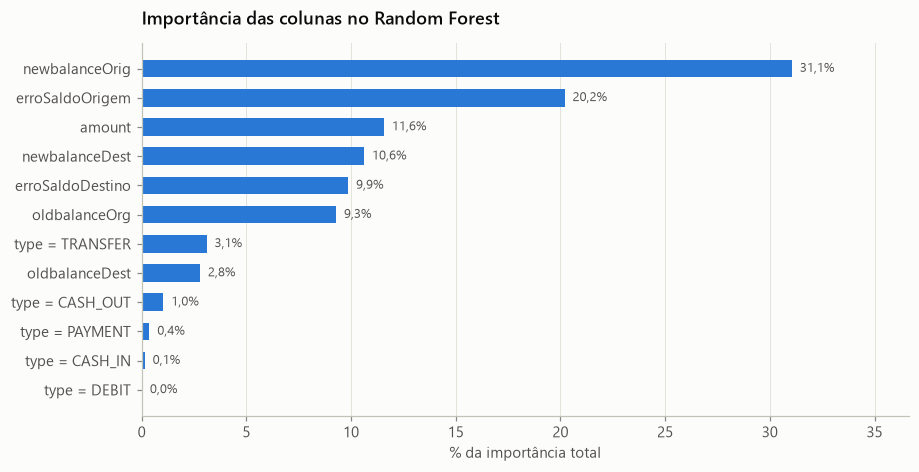

In [19]:
nomes = [nome.replace("remainder__", "").replace("tipo__type_", "type = ")
         for nome in modelo_final.named_steps["preprocessamento"].get_feature_names_out()]
importancia = pd.Series(modelo_final.named_steps["floresta"].feature_importances_, index=nomes).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh(importancia.index, importancia * 100, color=COR_NORMAL, height=0.6)
for posicao, valor in enumerate(importancia):
    ax.text(valor * 100, posicao, "  " + pct(valor, 1), va="center", color=TINTA_2, fontsize=8.5)
ax.set_xlim(0, importancia.max() * 100 * 1.18)
ax.set(title="Importância das colunas no Random Forest", xlabel="% da importância total")
ax.grid(axis="y", visible=False)
plt.show()

As colunas que o modelo mais usa são exatamente as que a seção 2.3 apontou: o **saldo final de quem envia**
(`newbalanceOrig`, 31%), que fica zerado quando o golpista esvazia a conta, e o **erro de saldo da origem** (20%),
criado na seção 3.1. Somando todas as colunas de saldo, inclusive os dois erros, são 84% da importância; o valor tem 12%
e o tipo da transação, menos de 5%. Depois que os saldos revelam o padrão, o tipo quase não acrescenta informação.

Importância alta não significa "causa": significa que o modelo usou muito aquela coluna para separar as classes.

### 5.5 Onde o modelo erra

In [20]:
previsto_final = (probabilidade_final >= LIMIAR).astype(int)
detalhes = X_teste.assign(isFraud=y_teste, probabilidade=probabilidade_final.round(3),
                          step=passo.loc[X_teste.index])
print("Fraudes que passaram (falsos negativos):")
display(detalhes[(y_teste == 1) & (previsto_final == 0)])
print("Normais bloqueadas por engano (falsos positivos):")
display(detalhes[(y_teste == 0) & (previsto_final == 1)])

parecidas = (X_teste["type"].isin(["TRANSFER", "CASH_OUT"]) & (X_teste["oldbalanceOrg"] == 0)
             & (X_teste["newbalanceOrig"] == 0) & (X_teste["erroSaldoDestino"].abs() < 0.01))
print("Transações do teste com o mesmo padrão das fraudes perdidas "
      "(origem 0 → 0 e saldo do destino fechando):")
padrao = parecidas.rename("padrão de saldo").map({False: "outro padrão", True: "mesmo padrão"})
pd.crosstab(padrao, y_teste.rename("isFraud")).style.format(thousands=".")

Fraudes que passaram (falsos negativos):


,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,erroSaldoOrigem,erroSaldoDestino,isFraud,probabilidade,step
77745,CASH_OUT,277970.88,0.00,0.0,0.00,277970.88,277970.88,0.00,1,0.014,10
543928,CASH_OUT,23292.30,0.00,0.0,392364.62,415656.92,23292.30,0.00,1,0.000,21
217978,TRANSFER,123194.95,79466.45,0.0,535933.16,263908.84,43728.50,395219.27,1,0.000,13
14861,CASH_OUT,181728.11,0.00,0.0,11397.00,184477.77,181728.11,8647.34,1,0.022,8


Normais bloqueadas por engano (falsos positivos):


,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,erroSaldoOrigem,erroSaldoDestino,isFraud,probabilidade,step


Transações do teste com o mesmo padrão das fraudes perdidas (origem 0 → 0 e saldo do destino fechando):


isFraud,0,1
padrão de saldo,,
mesmo padrão,197.184,5
outro padrão,1.073.697,1.638


**Nenhuma transação normal foi bloqueada.** As 4 fraudes que passaram receberam entre 0% e 2,2% de probabilidade: o
modelo não "quase acertou", ele as viu como normais.

Três delas vêm de contas que **já começavam com saldo 0** (origem 0 → 0). Esse padrão aparece em 47% das transações
normais e em só 0,5% das fraudes (seção 2.3). Como a conta não tinha saldo, essas fraudes não têm a assinatura do golpe
(esvaziar a conta). A última tabela mostra o tamanho do problema: no teste, **197.184 transações normais** têm o mesmo
padrão das duas fraudes perdidas mais típicas (origem 0 → 0 e saldo do destino fechando), contra **só 5 fraudes**.
Com as seis informações que o Java envia, esses casos são iguais a quase 200 mil transações legítimas, e nenhum ajuste
de modelo ou de limiar separa casos com os mesmos dados.

Para pegá-los seria preciso informação nova, como o histórico da conta: no PaySim, o golpe é uma `TRANSFER` seguida de
um `CASH_OUT` do mesmo valor. Isso exigiria que o Java enviasse transações anteriores, e fica como trabalho futuro.

### 5.6 O resultado se sustenta?

Três verificações para saber se o resultado não foi sorte nem depende de detalhes da divisão:

1. **Outras divisões aleatórias** (sementes 1, 2 e 3): quanto o resultado varia só pelo sorteio de treino e teste.
2. **Divisão temporal:** treinar com as primeiras horas da simulação e testar com as últimas, como aconteceria em
   produção (o modelo é treinado com o passado e usado no futuro).
3. **Hora do dia como coluna extra:** verifica se vale a pena pedir mais esse campo ao Java (seção 1.5).

In [21]:
def treinar_e_avaliar(nome, X_treino_, y_treino_, X_teste_, y_teste_, semente=SEMENTE):
    X_a, y_a = train.amostrar_treino(X_treino_, y_treino_)
    modelo = train.criar_modelo().set_params(floresta__random_state=semente)
    modelo.fit(X_a, y_a)
    probabilidade = modelo.predict_proba(X_teste_)[:, 1]
    return metricas(nome, y_teste_, probabilidade), probabilidade


verificacoes = [metricas("divisão aleatória, semente 42 (modelo escolhido)", y_teste, probabilidade_final)]
for semente in (1, 2, 3):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=semente)
    verificacoes.append(treinar_e_avaliar(f"divisão aleatória, semente {semente}", X_tr, y_tr, X_te, y_te,
                                          semente)[0])
    del X_tr, X_te, y_tr, y_te

corte = int(passo.quantile(0.8))
passado, futuro = passo <= corte, passo > corte
linha_temporal, probabilidade_temporal = treinar_e_avaliar(
    f"temporal: treina até a hora {corte}, testa depois", X[passado], y[passado], X[futuro], y[futuro])
verificacoes.append(linha_temporal)

X_hora = X.assign(hora=passo % 24)
X_tr, X_te, y_tr, y_te = train_test_split(X_hora, y, test_size=0.2, stratify=y, random_state=SEMENTE)
verificacoes.append(treinar_e_avaliar("com a hora do dia (semente 42)", X_tr, y_tr, X_te, y_te)[0])
del X_hora, X_tr, X_te, y_tr, y_te

print(f"Divisão temporal: treino com {milhar(passado.sum())} transações (horas 1 a {corte}), "
      f"teste com {milhar(futuro.sum())} (horas {corte + 1} a {passo.max()}), "
      f"{pct(y[futuro].mean())} de fraude no teste")
tabela_metricas(verificacoes)

Divisão temporal: treino com 5.113.884 transações (horas 1 a 355), teste com 1.248.736 (horas 356 a 743), 0,34% de fraude no teste


,acurácia,precisão,recall,F1,AP,fraudes detectadas,fraudes que passaram,normais bloqueadas
modelo,,,,,,,,
"divisão aleatória, semente 42 (modelo escolhido)","99,9997%","100,00%","99,76%","99,88%","0,9983",1.639,4,0
"divisão aleatória, semente 1","99,9995%","100,00%","99,63%","99,82%","0,9971",1.637,6,0
"divisão aleatória, semente 2","99,9994%","100,00%","99,51%","99,76%","0,9973",1.635,8,0
"divisão aleatória, semente 3","99,9995%","100,00%","99,63%","99,82%","0,9990",1.637,6,0
"temporal: treina até a hora 355, testa depois","99,9998%","100,00%","99,95%","99,98%","1,0000",4.248,2,0
com a hora do dia (semente 42),"99,9997%","100,00%","99,76%","99,88%","0,9983",1.639,4,0


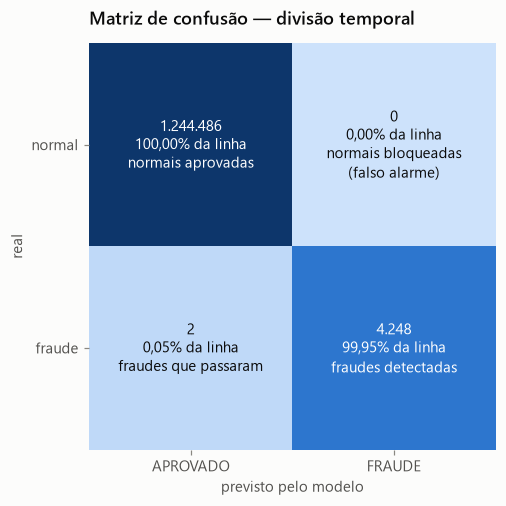

In [22]:
fig, ax = plt.subplots(figsize=(6.4, 4.8))
plotar_matriz(ax, y[futuro], probabilidade_temporal, "Matriz de confusão — divisão temporal")
plt.show()

- **Não foi sorte da divisão.** Com outras sementes, o modelo perde entre 4 e 8 fraudes (recall de 99,5% a 99,8%) e
  continua sem nenhum falso alarme. A semente 42 é a mais favorável das quatro, mas a diferença é de no máximo 4
  transações em 1.643. Qualquer "melhora" menor que isso, ao treinar de novo, seria apenas variação aleatória.
- **Funciona com dados do futuro.** Treinando com as horas 1 a 355 e testando com as horas 356 a 743, o modelo detecta
  4.248 de 4.250 fraudes, sem falso alarme. O padrão de fraude não muda ao longo da simulação.
- **A hora do dia não acrescenta nada.** O resultado com a coluna `hora` é idêntico ao modelo escolhido. Por isso ela
  ficou de fora, e o Java não precisa enviá-la.

### 5.7 Conclusões

1. **O Random Forest com as colunas de erro de saldo é a melhor das seis abordagens:** 99,76% de recall com 100% de
   precisão no teste, sem nenhum cliente bloqueado por engano.
2. **O maior ganho veio da transformação dos dados, e não só do algoritmo.** Criar `erroSaldoOrigem` e
   `erroSaldoDestino` levou o recall do Random Forest de 78% para 99,8%. A floresta, por sua vez, eliminou os 58 falsos
   alarmes da árvore única.
3. **O modelo chegou ao limite dos dados disponíveis.** As fraudes que passam são iguais, nas seis colunas, a milhares de
   transações normais, e o resultado varia mais pela sorte da divisão (4 a 8 fraudes perdidas) do que qualquer ajuste
   poderia ganhar. Treinar de novo não traria ganho mensurável.
4. **O resultado se sustenta** com outras divisões, com dados do futuro e com qualquer limiar entre 0,35 e 0,65.

**Limitações:**

- O PaySim é simulado, e o golpe dele tem uma assinatura muito clara (esvaziar a conta). Em dados reais de banco a
  detecção seria bem mais difícil; as métricas daqui não devem ser lidas como o desempenho esperado em produção.
- O treino usa 0,65% de fraude por causa da amostragem, então as probabilidades tendem a ficar acima da chance real.
  Para a decisão FRAUDE/APROVADO isso não importa, mas o número não é uma probabilidade calibrada.
- O modelo olha uma transação por vez. Golpes em várias etapas só seriam detectados com o histórico das contas.

## 6. Geração do modelo final

O modelo final é gerado pelo próprio `train.py` (mesma amostra, mesma semente e mesmos parâmetros avaliados acima), que
sobrescreve `models/modelo.pkl`. Em seguida chamamos o `predict.py` do mesmo jeito que o Java vai chamar: um processo
novo por transação, lendo apenas o stdout.

In [23]:
if versoes_diferentes:
    raise RuntimeError(f"O modelo.pkl não foi gerado: versões diferentes do requirements.txt {versoes_diferentes}. "
                       "Um .pkl salvo com outra versão do scikit-learn pode falhar no predict.py.")
train.main()

Lendo PS_20174392719_1491204439457_log.csv...


6,362,620 transações, 8,213 fraudes (0.13%)



Treinando Random Forest com 1,006,570 transações (6,570 fraudes)...



Avaliação em 1,272,524 transações que o modelo não viu (limiar 0.5):


              precision    recall  f1-score   support

    APROVADO     1.0000    1.0000    1.0000   1270881
      FRAUDE     1.0000    0.9976    0.9988      1643

    accuracy                         1.0000   1272524
   macro avg     1.0000    0.9988    0.9994   1272524
weighted avg     1.0000    1.0000    1.0000   1272524

Fraudes detectadas: 1,639 | fraudes que passaram: 4
Normais aprovadas:  1,270,881 | normais bloqueadas por engano: 0

Modelo salvo em C:\Users\jonat\projeto_fraude_ai\fim-do-semestre-fraude-ai\ml\models\modelo.pkl (0.5 MB) em 30s


In [24]:
exemplos = {
    "fraude real do dataset (TRANSFER que esvazia a conta)": [
        "--tipo", "TRANSFER", "--valor", "181.00", "--saldo-origem-antes", "181.00",
        "--saldo-origem-depois", "0", "--saldo-destino-antes", "0", "--saldo-destino-depois", "0"],
    "pagamento normal do dataset": [
        "--tipo", "PAYMENT", "--valor", "9839.64", "--saldo-origem-antes", "170136.00",
        "--saldo-origem-depois", "160296.36", "--saldo-destino-antes", "0", "--saldo-destino-depois", "0"],
    "entrada inválida (valor com vírgula)": [
        "--tipo", "TRANSFER", "--valor", "181,00", "--saldo-origem-antes", "181.00",
        "--saldo-origem-depois", "0", "--saldo-destino-antes", "0", "--saldo-destino-depois", "0"],
}
for nome, argumentos in exemplos.items():
    resultado = subprocess.run([sys.executable, "predict.py", *argumentos], capture_output=True, text=True)
    erro = resultado.stderr.strip().splitlines()[-1] if resultado.stderr.strip() else "(vazio)"
    print(f"{nome}\n  código de saída: {resultado.returncode}\n  stdout: {resultado.stdout.strip() or '(vazio)'}"
          f"\n  stderr: {erro}\n")
print(f"Notebook executado em {(time.time() - inicio_notebook) / 60:.1f} minutos")

fraude real do dataset (TRANSFER que esvazia a conta)
  código de saída: 0
  stdout: {"resultado": "FRAUDE", "probabilidade": 0.9937}
  stderr: (vazio)



pagamento normal do dataset
  código de saída: 0
  stdout: {"resultado": "APROVADO", "probabilidade": 0.0}
  stderr: (vazio)



entrada inválida (valor com vírgula)
  código de saída: 2
  stdout: (vazio)
  stderr: predict.py: error: argument --valor: '181,00' nao e um numero (use ponto como separador decimal)

Notebook executado em 4.9 minutos
